# Week 10 In-Class Exercise: Unsupervised Learning — Clustering Handwritten Digits

In the textbook (Chapter 9), we studied how to find structure in data **without labels**: **K-Means** (and how to pick the number of clusters `k` with the *elbow* on inertia and the *silhouette* score), clustering for **semi-supervised learning** (label a few representative points instead of everything), **DBSCAN** (density-based clustering that finds arbitrary shapes and flags outliers), and **Gaussian Mixtures** (soft, probabilistic cluster assignments that double as an anomaly detector).

In this exercise, you'll apply those **same concepts** to a dataset you've seen before:

> **Digits** — 1,797 images of handwritten digits (0-9), each an 8x8 grayscale image flattened into **64 features**. It ships with scikit-learn, so there is nothing to download.

Crucially, clustering is **unsupervised**: we will *hide* the digit labels and ask the algorithms to discover the 10 groups on their own. We only peek at the true labels at the end to *score* how well the clusters lined up. Every technique from the chapter transfers directly — your job is to adapt the code, not invent new methods.

You'll follow the same workflow as Chapter 9:
1. Load the data and set the labels aside
2. Run **K-Means** and look at the cluster centers as images
3. Find the best `k` with the **elbow** (inertia) and the **silhouette** score
4. Measure how well the clusters match the true digits
5. Use clustering for **semi-supervised learning**
6. Run **DBSCAN** on a non-convex toy dataset
7. Fit a **Gaussian Mixture** and use it to flag the most anomalous images

### Useful API References

| Task | Documentation |
|------|---------------|
| Load data | [sklearn.datasets.load_digits](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html) |
| K-Means | [cluster.KMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html) |
| Silhouette score | [metrics.silhouette_score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html) |
| Cluster vs labels | [adjusted_rand_score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_rand_score.html), [confusion_matrix](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html) |
| DBSCAN | [cluster.DBSCAN](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html) |
| Gaussian Mixture | [mixture.GaussianMixture](https://scikit-learn.org/stable/modules/generated/sklearn.mixture.GaussianMixture.html) |
| Toy data | [make_moons](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_moons.html) |
| Classifier | [linear_model.LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html) |

<table align="left">
  <td>
    <a href="https://colab.research.google.com/github/pjmcswee/IST707-Notebooks/blob/main/week10/week10_inclass_exercise.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>
  </td>
</table>

## Setup

Run this cell to import the libraries and set the plotting defaults.

In [22]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

plt.rc('font', size=13)
plt.rc('axes', labelsize=13, titlesize=13)
plt.rc('legend', fontsize=11)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

RANDOM_STATE = 42

## Step 1: Load the Data and Hide the Labels (Provided)

Each row is one 8x8 image flattened into 64 pixel-intensity values (0-16). We keep the true labels `y` only to *evaluate* the clustering later — the clustering algorithms never see them. This cell is provided — just run it.

In [23]:
from sklearn.datasets import load_digits

digits = load_digits()
X = digits.data       # shape (1797, 64) — the only thing clustering gets to see
y = digits.target     # shape (1797,)  — hidden from clustering, used only to score

print('Data shape:', X.shape)
print('True classes (for scoring only):', np.unique(y))
print('There are', len(np.unique(y)), 'digit classes, so we expect ~10 natural clusters.')

Data shape: (1797, 64)
True classes (for scoring only): [0 1 2 3 4 5 6 7 8 9]
There are 10 digit classes, so we expect ~10 natural clusters.


## Step 2: Run K-Means and Look at the Cluster Centers

K-Means partitions the data into `k` clusters, each represented by a **centroid** (the mean of its members). Because each image is 64 numbers, each centroid is *also* 64 numbers — so we can reshape a centroid back into an 8x8 image and literally *see* the "average digit" that cluster found.

**Your turn!**
1. Fit `KMeans(n_clusters=10, n_init=10, random_state=RANDOM_STATE)` on `X` and get the cluster assignments.
2. Reshape each of the 10 cluster centers to 8x8 and display them in a row of images.

**Hint (from the chapter):**
```python
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=10, n_init=10, random_state=RANDOM_STATE)
y_pred = kmeans.fit_predict(X)
kmeans.cluster_centers_   # shape (10, 64); reshape a row with .reshape(8, 8)
```

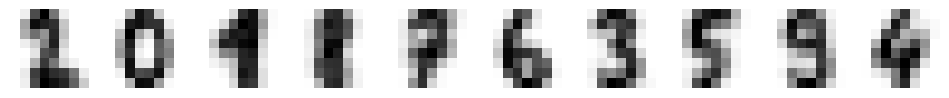

In [24]:
from sklearn.cluster import KMeans

# TODO: Fit KMeans with 10 clusters; display the 10 cluster centers as 8x8 images.
# Your code here:

kmeans = KMeans(n_clusters=10, n_init=10, random_state=RANDOM_STATE)
y_pred = kmeans.fit_predict(X)
kmeans.cluster_centers_

fig, axes = plt.subplots(1, 10, figsize=(12, 2))
for ax, center in zip(axes, kmeans.cluster_centers_):
    ax.imshow(center.reshape(8, 8), cmap='binary')
    ax.axis('off')
plt.show()





**Question:** Look at the 10 centroid images. Do most of them resemble recognizable digits? Since K-Means never saw a single label, what does it mean that the "average" of each cluster still looks digit-like?

*Your answer:* Most of the digits do still look recongizable, only 1 of them is too blurry to makeout what it is. I think that the average of eahc cluster still loooks digit-like means that taking the average of all 64 values for each digit will result in 64 values that closely resemble the rest of the images in the cluster.



## Step 3: How Many Clusters? The Elbow and the Silhouette

In real unsupervised problems you don't know `k` in advance. Two standard tools help you choose it:
- **Inertia** (within-cluster sum of squared distances) always drops as `k` grows; you look for the *elbow* where it stops dropping sharply.
- The **silhouette score** (−1 to 1, higher is better) measures how well-separated the clusters are and usually has a clear peak.

**Your turn!**
1. For `k` from 2 to 15, fit `KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)` and record both `kmeans.inertia_` and the `silhouette_score(X, kmeans.labels_)`.
2. Plot inertia vs `k` and silhouette vs `k` side by side.

**Hint (from the chapter):**
```python
from sklearn.metrics import silhouette_score
kmeans_per_k = [KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
                for k in range(2, 16)]
inertias = [m.inertia_ for m in kmeans_per_k]
silhouettes = [silhouette_score(X, m.labels_) for m in kmeans_per_k]
```

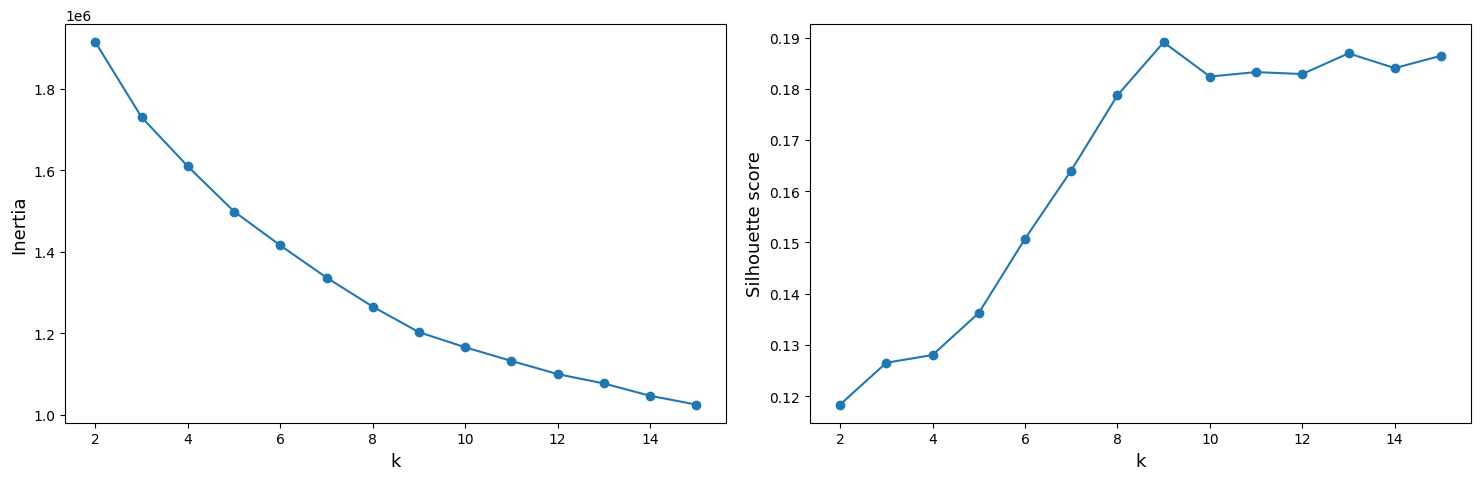

In [25]:
from sklearn.metrics import silhouette_score

# TODO: Sweep k from 2..15; plot inertia vs k and silhouette vs k side by side.
# Your code here:

kmeans_per_k = [KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)for k in range(2, 16)]
inertias = [m.inertia_ for m in kmeans_per_k]
silhouettes = [silhouette_score(X, m.labels_) for m in kmeans_per_k]

k_range = range(2,16)

fig, axes = plt.subplots(1, 2, figsize = (15,5))
axes[0].plot(k_range, inertias, 'o-')
axes[0].set_xlabel('k'); axes[0].set_ylabel('Inertia')
axes[1].plot(k_range, silhouettes, 'o-')
axes[1].set_xlabel('k'); axes[1].set_ylabel('Silhouette score')
plt.tight_layout()

**Question:** Which `k` does the silhouette score prefer, and where is the elbow in the inertia curve? We *know* there are 10 digit classes — did either method land exactly on 10? Give one reason the best clustering `k` might not equal the true number of classes.

*Your answer:* Silhoutte score prefers a k of 9, and for inertia its hard to tell, but I think the curve also starts to flatten out around k of 9 as well. One reason the best clustering k might not equal the true number of classes is because numbers like 4 and 9 are very similar, so mathematically, there points might be close enough that they should be grouped together in one cluster.



## Step 4: How Well Do the Clusters Match the True Digits?

Now we *finally* use the hidden labels `y` — only to **score** the `k=10` clustering from Step 2. Cluster numbers are arbitrary (cluster "3" has nothing to do with the digit 3), so we can't compare them directly. The **Adjusted Rand Index** compares two groupings regardless of how the labels are numbered: 1.0 = identical grouping, 0.0 = random.

**Your turn!**
1. Compute `adjusted_rand_score(y, y_pred)` for your 10-cluster K-Means result.
2. Build a `confusion_matrix(y, y_pred)` (true digit vs cluster id) and display it with `ConfusionMatrixDisplay` to see which digits landed in which clusters.

**Hint (from the chapter):**
```python
from sklearn.metrics import adjusted_rand_score, confusion_matrix, ConfusionMatrixDisplay
ari = adjusted_rand_score(y, y_pred)
cm = confusion_matrix(y, y_pred)
ConfusionMatrixDisplay(cm).plot()
```

Adjusted Rand Index 0.667


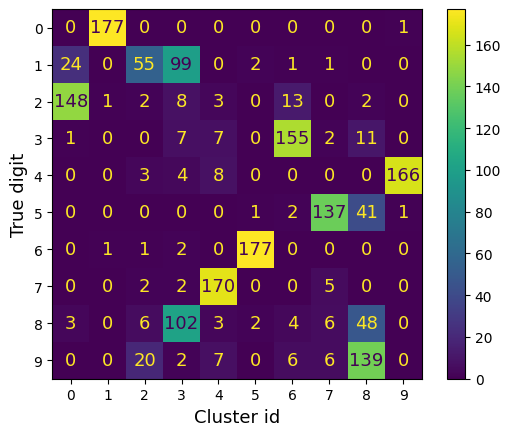

In [26]:
from sklearn.metrics import adjusted_rand_score, confusion_matrix, ConfusionMatrixDisplay

# TODO: Print the adjusted Rand index and show the (true digit) x (cluster id)
#       confusion matrix.
# Your code here:

ari = adjusted_rand_score(y, y_pred)
cm = confusion_matrix(y, y_pred)
ConfusionMatrixDisplay(cm).plot()

print(f'Adjusted Rand Index {ari:.3f}')

plt.xlabel('Cluster id'); plt.ylabel('True digit')
plt.show()

**Question:** The adjusted Rand index is well above 0 (random) but well below 1 (perfect). Using your confusion matrix, name one pair of digits that K-Means tended to merge or split, and give a visual reason why those digits are hard to separate without labels.

*Your answer:* One pair of digits that k-means tended to merge was 4 and 9. This is likely because they are very similar, with the only difference being the top of a 4 is not closed, and the top of a 9 is, which is easily confused especially in lower resolutions.



## Step 5: Clustering for Semi-Supervised Learning

Imagine labeling digits is expensive and you can only afford to label **50** images. Labeling the *first* 50 is wasteful — many will be near-duplicates. A smarter move (from the chapter): cluster into 50 groups, label only the one image closest to each centroid (the *representative* of its group), and train on those 50 hand-picked images.

**Your turn!**
1. Split: `X_train, y_train = X[:1400], y[:1400]` and `X_test, y_test = X[1400:], y[1400:]`.
2. **Baseline:** train `LogisticRegression(max_iter=10000)` on the *first* 50 training images and print its test accuracy.
3. **Representative:** run `KMeans(n_clusters=50, n_init=10, random_state=RANDOM_STATE)` on `X_train`; for each of the 50 clusters find the training image closest to that centroid; label those 50 representatives (using `y_train` as the "human"); train a fresh LogisticRegression on them and print its test accuracy.

**Hint (from the chapter):**
```python
from sklearn.linear_model import LogisticRegression
kmeans = KMeans(n_clusters=50, n_init=10, random_state=RANDOM_STATE)
X_digits_dist = kmeans.fit_transform(X_train)        # distance to each centroid
rep_idx = np.argmin(X_digits_dist, axis=0)           # closest image per cluster
X_rep, y_rep = X_train[rep_idx], y_train[rep_idx]
```

In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# TODO: Compare test accuracy of (a) training on the first 50 labels vs
#       (b) training on 50 cluster representatives.
# Your code here:

X_train, y_train = X[:1400], y[:1400]

X_test, y_test = X[1400:], y[1400:]

lr_rand_50 = LogisticRegression(max_iter = 10000).fit(X_train[:50], y_train[:50])

lr_rand_preds = lr_rand_50.predict(X_test)


kmeans = KMeans(n_clusters=50, n_init=10, random_state=RANDOM_STATE)
X_digits_dist = kmeans.fit_transform(X_train)        # distance to each centroid
rep_idx = np.argmin(X_digits_dist, axis=0)           # closest image per cluster
X_rep, y_rep = X_train[rep_idx], y_train[rep_idx]

lr_best_50 = LogisticRegression(max_iter = 10000).fit(X_rep, y_rep)

lr_best_preds = lr_best_50.predict(X_test)

print(f'Logistic Regression Accuracy trianed on first 50 images: {accuracy_score(y_test, lr_rand_preds):.3f}')
print(f'Logistic Regression Accuracy trained on best representative images: {accuracy_score(y_test, lr_best_preds):.3f}')

Logistic Regression Accuracy trianed on first 50 images: 0.758
Logistic Regression Accuracy trained on best representative images: 0.839


**Question:** Both models were trained on exactly 50 labeled images, yet the representative approach should score noticeably higher. Why does picking one image per cluster give the classifier a better 50 to learn from than simply taking the first 50?

*Your answer:* Picking one image per cluster performed better than taking the first 50 because there is a chance the first 50 images didn't contain all 10 classes. Additionally, of the first 50, some of them might've been images that poorly represent their class, for example a 4 that has an almost closed loop that looks similar to a 9. Using the best image per cluster ensures that the images that were chosen are the most representative of their class.



## Step 6: DBSCAN — Clusters That Aren't Round

K-Means assumes clusters are roughly round blobs of similar size, so it fails on shapes like two interleaving crescents. **DBSCAN** groups points by *density* instead, so it can trace arbitrary shapes and label low-density points as outliers (`-1`).

**Your turn!** On the provided `make_moons` data:
1. Fit `KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE)` and scatter-plot the two clusters.
2. Fit `DBSCAN(eps=0.2, min_samples=5)` and scatter-plot its clusters (color by `dbscan.labels_`).
3. Put the two plots side by side.

**Hint (from the chapter):**
```python
from sklearn.cluster import DBSCAN
dbscan = DBSCAN(eps=0.2, min_samples=5).fit(X_moons)
plt.scatter(X_moons[:, 0], X_moons[:, 1], c=dbscan.labels_, cmap='Paired')
```

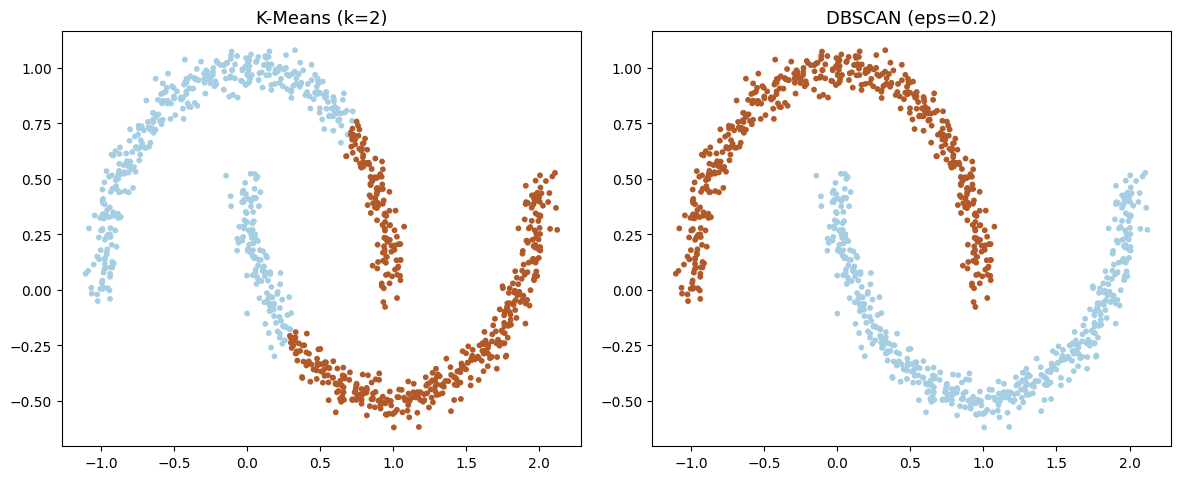

In [28]:
from sklearn.datasets import make_moons
from sklearn.cluster import DBSCAN

# Provided: a non-convex toy dataset (two interleaving crescents).
X_moons, y_moons = make_moons(n_samples=1000, noise=0.05, random_state=RANDOM_STATE)

# TODO: Cluster X_moons with KMeans(2) and with DBSCAN(eps=0.2); plot both
#       side by side, colored by the cluster each assigns.
# Your code here:

kmeans_moons = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE)
km_labels = kmeans_moons.fit_predict(X_moons)

dbscan = DBSCAN(eps=0.2, min_samples=5).fit(X_moons)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(X_moons[:, 0], X_moons[:, 1], c=km_labels, cmap='Paired', s=10)
axes[0].set_title('K-Means (k=2)')

axes[1].scatter(X_moons[:, 0], X_moons[:, 1], c=dbscan.labels_, cmap='Paired', s=10)
axes[1].set_title('DBSCAN (eps=0.2)')

plt.tight_layout()
plt.show()



**Question:** K-Means splits the two crescents with a straight boundary and gets them wrong; DBSCAN recovers the two arcs. Explain in one or two sentences *why* K-Means cannot capture this shape but DBSCAN can — refer to what each algorithm actually optimizes.

*Your answer:* K-means cannot capture this shape because it assumes each cluster is an elipse shape, which you can kind of make out in the graph on the left. DBSCAN is able to capture this shape because because it chains multiple spherical clusters to trace out a shape.



## Step 7: Gaussian Mixtures for Anomaly Detection

A **Gaussian Mixture Model (GMM)** assumes the data was generated from a mix of several Gaussian blobs. Unlike K-Means' hard assignments, it gives each point a *probability density* under the model — and points with very **low** density are natural **anomalies** (unusual or malformed images).

**Your turn!** On the digits data `X`:
1. Fit `GaussianMixture(n_components=10, n_init=5, random_state=RANDOM_STATE)`.
2. Use `gm.score_samples(X)` to get each image's log-density, then find the **6 lowest-density** images and display them as 8x8 pictures.

**Hint (from the chapter):**
```python
from sklearn.mixture import GaussianMixture
gm = GaussianMixture(n_components=10, n_init=5, random_state=RANDOM_STATE).fit(X)
densities = gm.score_samples(X)          # log-likelihood of each image
worst = np.argsort(densities)[:6]        # the 6 most anomalous
```

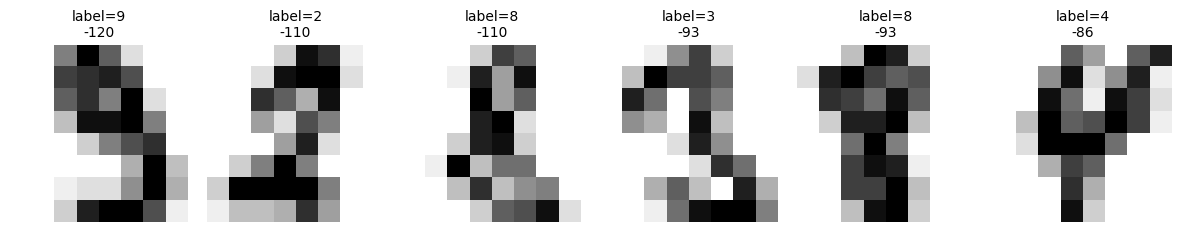

In [29]:
from sklearn.mixture import GaussianMixture

# TODO: Fit a 10-component GaussianMixture; display the 6 lowest-density
#       (most anomalous) digit images.
# Your code here:

gm = GaussianMixture(n_components=10, n_init=5, random_state=RANDOM_STATE).fit(X)
densities = gm.score_samples(X)
worst = np.argsort(densities)[:6]


fig, axes = plt.subplots(1, 6, figsize=(12, 2.5))
for ax, idx in zip(axes, worst):
    ax.imshow(X[idx].reshape(8, 8), cmap='binary')
    ax.set_title(f'label={y[idx]}\n{densities[idx]:.0f}', fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()


**Question:** Look at the 6 flagged images. Why might these particular digits have the lowest density under the model — what makes them unusual compared to a typical, cleanly written digit?

*Your answer:* I'm not totally sure but I think these images have the lowest density under the model because they are the least similar to other similar images. THey are unusual compared to a typical cleanly written digit I think because there resulution is much worse, the pixels here look larger than the pixels in the other images.



## Reflection Questions

Answer each question in the cell below it (1-3 sentences each).

**Q1:** All of this week's methods are **unsupervised** — they ran without labels. In Step 4 we scored K-Means against the true digits and got a decent-but-imperfect match. In what kind of real problem would you have *no* labels at all to check against, and how would you decide whether your clustering is any good in that situation?

*Your answer:* A real world problem where you would have no labels at all to check is if you have a bunch of peices of text and want to cluster them together by passages that have simmilar meaning. You can check if the clusters are any good by analyzing a sample of text per cluster and determining if the passages are similar.



**Q2:** You used three clustering algorithms: K-Means, DBSCAN, and Gaussian Mixtures. For each, name one situation where it is the *right* tool and one weakness that would make you avoid it.

*Your answer:* K-Means is the right tool when clusters are roughly round and similar in size and you already have a good guess for k, like the digits data, but it struggles with non-convex shapes like the moons and forces every point into a cluster even if it is an outlier. DBSCAN is the right tool for clusters with arbitrary shapes and for flagging outliers without choosing k, but it is very sensitive to eps and min_samples and has trouble when clusters have different densities. Gaussian Mixtures are the right tool when you want soft, probabilistic assignments or a density score for anomaly detection, like in Step 7, but they assume the data comes from Gaussian blobs and can be slow and unstable in high dimensions or with many components.

**Q3:** Step 5 showed clustering making a *supervised* model better with far fewer labels. Weeks 9 and 10 both reduced the work a model needs (PCA cut features; clustering cut labels). In your own words, what is the common theme — why is finding structure in data *before* training a predictive model so often worthwhile?

*Your answer:* Finding a structure in data before trianing a predictive model is often worthwile because training a predictive model on a large amount of data which is typical in the real world is costly and time consuming. Finding structure in the data reduces training time, while also sometimes increasing the performance of the model and justifying creating the model in the first place.

